AI Email Generator

In [78]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv

In [79]:
load_dotenv()

True

In [80]:
model = ChatOpenAI(
  model_name = 'gpt-4o',
  api_key = os.environ.get('OPENAI_API_KEY')
)

In [81]:
class EmailState(TypedDict):
    topic: str
    recipient: str
    purpose: str
    tone: str
    key_points: str
    
    draft: str
    improved_email: str
    adjust_tone: str
    format_email: str

In [82]:
def text_generator(state: EmailState) -> dict[str, str]:
  prompt = f"""
  {state['topic']}

  Generate a clear and professional email based on the following information:

  Recipient: {state['recipient']}
  Purpose: {state['purpose']}
  Tone: {state['tone']}
  Key Points: {state['key_points']}

  Requirements:
  - Write a complete email draft.
  - Keep the email concise and natural.
  - Follow the requested tone.
  - Clearly communicate the purpose.
  - Include an appropriate greeting and closing.
  - Do not add information that was not provided.
  - Do not include explanations outside the email.

  Return only the email draft.
  """

  response = model.invoke(prompt)

  return{'draft': response.content}


In [83]:
def improve_email(state: EmailState) -> dict[str, str]:
    prompt = f"""
    
    Improve the following email:

    {state['draft']}

    R    equirements:
    - Fix grammar and spelling mistakes.
    - Improve clarity and readability.
    - Make the email sound natural and professional.
    - Keep the original meaning.
    - Do not add new information.
    - Keep it concise.
    - Return only the improved email.

    Improved email:
    """

    response = model.invoke(prompt)

    return {
        "improved_email": response.content
    }


In [84]:
def adjust_tone(state: EmailState) -> dict[str, str]:
  
  prompt = f"""You are an expert email editor.

  Rewrite the following email according to the requested tone.

  Email:
  {state['improved_email']}

  Requested tone:
  {state['tone']}

  Requirements:
  - Keep the original meaning and key information.
  - Adjust the wording to match the requested tone.
  - Make the email natural, clear, and professional.
  - Do not add new information.
  - Keep it concise.
  - Return only the revised email."""

  response = model.invoke(prompt)
  return{'adjust_tone': response.content}

In [85]:
def format_email(state: EmailState) -> dict[str, str]:
  prompt = f"""You are an expert email formatter.

  Format the following email into a complete, professional email:

  Email:
  {state['adjust_tone']}

  Recipient:
  {state['recipient']}

  Requirements:
  - Add an appropriate subject line.
  - Add a suitable greeting.
  - Organize the email into clear paragraphs.
  - Add an appropriate closing and sign-off.
  - Preserve the original meaning and information.
  - Do not add new information.
  - Keep the formatting clean and professional.
  - Return only the final formatted email.
  """

  response = model.invoke(prompt)
  return{'format_email':response.content}


In [86]:
graph = StateGraph(EmailState)

graph.add_node('text_generator',text_generator)
graph.add_node('improve_email',improve_email)
graph.add_node('adjust_tone',adjust_tone)
graph.add_node('format_email',format_email)

graph.add_edge(START,'text_generator')
graph.add_edge('text_generator','improve_email')
graph.add_edge('improve_email','adjust_tone')
graph.add_edge('adjust_tone','format_email')
graph.add_edge('format_email',END)


In [87]:
workflow = graph.compile()

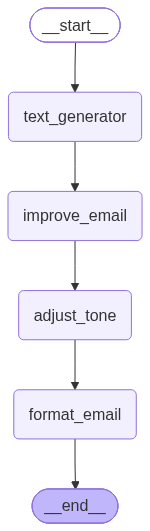

In [88]:
workflow

In [ ]:
initial = {
  'topic': 'Email to University Professor',
  'recipient': 'professor',
  'purpose': '2 days leave due to health issues',
  'tone': 'respectfully',
  'key_points': '2 days leave',
  'draft': '',
  'improved_email': '',
  'adjust_tone':'',
  'format_email': ''
}
result = workflow.invoke(initial)
print(result)

{'topic': 'Email to University Professor', 'recipient': 'professor', 'purpose': '2 days leave due to health issues', 'tone': 'respectfully', 'key_points': '2 days leave', 'draft': 'Subject: Request for Leave Due to Health Issues\n\nDear Professor [Last Name],\n\nI hope this message finds you well. I am writing to inform you that I am experiencing some health issues and would like to request a leave of absence for two days. I plan to resume my responsibilities on [return date].\n\nPlease let me know if you need any further information. I appreciate your understanding and support.\n\nThank you for your consideration.\n\nSincerely,\n[Your Full Name]  \n[Your Contact Information]', 'improved_email': 'Subject: Request for Leave Due to Health Issues\n\nDear Professor [Last Name],\n\nI hope this message finds you well. I am writing to request a leave of absence for two days due to health issues. I intend to resume my responsibilities on [return date].\n\nPlease let me know if you require any 

In [ ]:
""" draft
    improved_email
    adjust_tone
    format_email"""

print(result['draft'])

Subject: Request for Leave Due to Health Issues

Dear Professor [Last Name],

I hope this message finds you well. I am writing to inform you that I am experiencing some health issues and would like to request a leave of absence for two days. I plan to resume my responsibilities on [return date].

Please let me know if you need any further information. I appreciate your understanding and support.

Thank you for your consideration.

Sincerely,
[Your Full Name]  
[Your Contact Information]


In [98]:
print(result['format_email'])

Subject: Request for Leave of Absence Due to Health Issues

Dear Professor [Last Name],

I hope this message finds you well.

I am writing to respectfully request a leave of absence for two days due to health issues. I plan to resume my duties on [return date].

Please let me know if you require any further information. I am grateful for your understanding and support.

Thank you for considering my request.

Sincerely,  
[Your Full Name]  
[Your Contact Information]
